<a href="https://colab.research.google.com/github/Saransh-Basu-01/Understanding-Deep-learning-/blob/main/Chapter_10_Convolutions_For_Mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 10.5: Convolution for MNIST

In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import random
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [2]:
# Run this once to load the train and test data straight into a dataloader class
# that will provide the batches

# (It may complain that some files are missing because the files seem to have been
# reorganized on the underlying website, but it still seems to work). If everything is working
# properly, then the whole notebook should run to the end without further problems
# even before you make changes.
batch_size_train = 64
batch_size_test = 1000

# TODO Change this directory to point towards an existing directory (No change needed if using Google Colab)
myDir = '/files/'

train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)


100%|██████████| 9.91M/9.91M [00:01<00:00, 4.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.3MB/s]


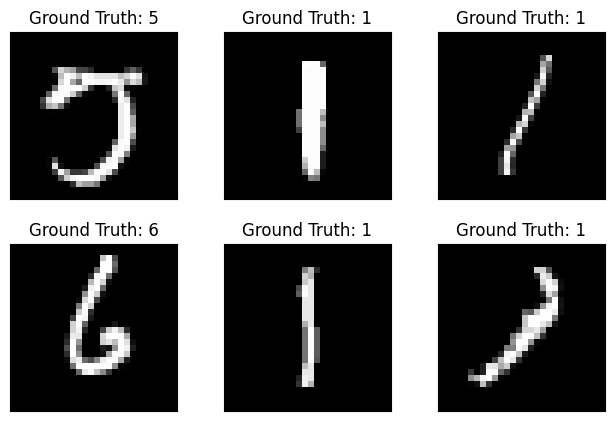

In [3]:

# Let's draw some of the training data
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Ground Truth: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()

In [4]:

from os import X_OK
# TODO Change this class to implement
# 1. A valid convolution with kernel size 5, 1 input channel and 10 output channels
# 2. A max pooling operation over a 2x2 area
# 3. A Relu
# 4. A valid convolution with kernel size 5, 10 input channels and 20 output channels
# 5. A 2D Dropout layer
# 6. A max pooling operation over a 2x2 area
# 7. A relu
# 8. A flattening operation
# 9. A fully connected layer mapping from (whatever dimensions we are at-- find out using .shape) to 50
# 10. A ReLU
# 11. A fully connected layer mapping from 50 to 10 dimensions
# 12. A softmax function.

# Replace this class which implements a minimal network (which still does okay)
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # 1. Valid convolution: 1 in, 10 out, kernel 5
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
        # 2. Max pool 2x2
        self.pool1 = nn.MaxPool2d(kernel_size=2)
        # 3. ReLU
        self.relu = nn.ReLU()
        # 4. Valid conv: 10 in, 20 out, kernel 5
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
        # 5. 2D Dropout
        self.drop = nn.Dropout2d()
        # 6. Max pool 2x2
        self.pool2 = nn.MaxPool2d(kernel_size=2)
        # 8. Flatten
        self.flat = nn.Flatten()
        # 9. FC: computed dynamically below
        self.fc1 = nn.Linear(20 * 4 * 4, 50)   # depends on input size
        # 11. FC: 50 -> 10
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = self.conv1(x)      # (N,10,24,24) for 28x28 input
        x = self.pool1(x)      # (N,10,12,12)
        x = self.relu(x)
        x = self.conv2(x)      # (N,20,8,8)
        x = self.drop(x)
        x = self.pool2(x)      # (N,20,4,4)
        x = self.relu(x)
        x = self.flat(x)       # (N,320)
        x = self.fc1(x)        # (N,50)
        x = self.relu(x)       # (or F.relu(x))
        x = self.fc2(x)        # (N,10)
        x = F.log_softmax(x, dim=1)
        return x

In [5]:


# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

In [7]:

# Create network
model = Net().to(device)
# Initialize model weights
model.apply(weights_init)
# Define optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

In [9]:

# Main training routine
def train(epoch):
  model.train()
  # Get each
  for batch_idx, (data, target) in enumerate(train_loader):
    data = data.to(device)
    target = target.to(device)
    optimizer.zero_grad()
    output = model(data)
    loss = F.nll_loss(output, target)
    loss.backward()
    optimizer.step()
    # Store results
    if batch_idx % 10 == 0:
      print('Train Epoch: {} [{}/{}]\tLoss: {:.6f}'.format(
        epoch, batch_idx * len(data), len(train_loader.dataset), loss.item()))

In [10]:

# Run on test data
def test():
  model.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      data = data.to(device)
      target = target.to(device)
      output = model(data)
      test_loss += F.nll_loss(output, target, size_average=False).item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))

In [11]:

# Get initial performance
test()
# Train for three epochs
n_epochs = 3
for epoch in range(1, n_epochs + 1):
  train(epoch)
  test()

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3236: UserWarning: size_average and reduce args will be deprecated, please use reduction='sum' instead.
  reduction = _Reduction.legacy_get_string(size_average, reduce)



Test set: Avg. loss: 2.5308, Accuracy: 1196/10000 (12%)

Train Epoch: 1 [0/60000]	Loss: 2.624716
Train Epoch: 1 [640/60000]	Loss: 2.167744
Train Epoch: 1 [1280/60000]	Loss: 2.156455
Train Epoch: 1 [1920/60000]	Loss: 1.969388
Train Epoch: 1 [2560/60000]	Loss: 1.772837
Train Epoch: 1 [3200/60000]	Loss: 1.517809
Train Epoch: 1 [3840/60000]	Loss: 1.489377
Train Epoch: 1 [4480/60000]	Loss: 1.087938
Train Epoch: 1 [5120/60000]	Loss: 1.131711
Train Epoch: 1 [5760/60000]	Loss: 0.939903
Train Epoch: 1 [6400/60000]	Loss: 0.681911
Train Epoch: 1 [7040/60000]	Loss: 0.694632
Train Epoch: 1 [7680/60000]	Loss: 0.810733
Train Epoch: 1 [8320/60000]	Loss: 0.721623
Train Epoch: 1 [8960/60000]	Loss: 1.000834
Train Epoch: 1 [9600/60000]	Loss: 0.770687
Train Epoch: 1 [10240/60000]	Loss: 0.631130
Train Epoch: 1 [10880/60000]	Loss: 0.840193
Train Epoch: 1 [11520/60000]	Loss: 0.731017
Train Epoch: 1 [12160/60000]	Loss: 0.694902
Train Epoch: 1 [12800/60000]	Loss: 0.447365
Train Epoch: 1 [13440/60000]	Loss: 0.4

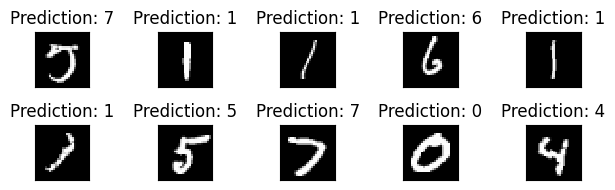

In [16]:
# Run network on data we got before and show predictions
example_data = example_data.to(device)      # <-- add this line
output = model(example_data)

fig = plt.figure()
for i in range(10):
    plt.subplot(5, 5, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0].cpu(), cmap='gray', interpolation='none')  # .cpu() for imshow
    plt.title("Prediction: {}".format(
        output.data.max(1, keepdim=True)[1][i].item()))
    plt.xticks([])
    plt.yticks([])
plt.show()

In [17]:
import torch
import torch.nn as nn


class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        self.features = nn.Sequential(
            # 1. Valid conv: 1 in, 10 out, kernel 5
            nn.Conv2d(1, 10, kernel_size=5),
            # 2. Max pool 2x2
            nn.MaxPool2d(kernel_size=2),
            # 3. ReLU
            nn.ReLU(),
            # 4. Valid conv: 10 in, 20 out, kernel 5
            nn.Conv2d(10, 20, kernel_size=5),
            # 5. 2D Dropout
            nn.Dropout2d(),
            # 6. Max pool 2x2
            nn.MaxPool2d(kernel_size=2),
            # 7. ReLU
            nn.ReLU(),
            # 8. Flatten
            nn.Flatten(),
        )

        self.classifier = nn.Sequential(
            # 9. FC: 20*4*4 -> 50  (28x28 input)
            nn.Linear(20 * 4 * 4, 50),
            # 10. ReLU
            nn.ReLU(),
            # 11. FC: 50 -> 10
            nn.Linear(50, 10),
            # 12. Softmax (log version for NLLLoss)
            nn.LogSoftmax(dim=1),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x